# Importing Libraries

In [1]:
!pip install imbalanced-learn

In [2]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [5]:
# Loading dataset
df = pd.read_csv("creditcard.csv")

# Basic Quality Checks for Dataset

In [6]:
# Head of the dataset
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Tail of the Dataset
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [8]:
# Shape of the Dataset
df.shape

(284807, 31)

In [9]:
# Columns
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [10]:
# Information of the Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [11]:
# Descriptive Statistics
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [12]:
#  Checking Missing Values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [13]:
# Checking Duplicate Values
df.duplicated().sum()

np.int64(1081)

In [14]:
# Removing duplicates
df = df.drop_duplicates()

In [15]:
# Shape after dropping duplicates
df.shape

(283726, 31)

In [16]:
# Checking Class Distribution
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [17]:
# Percentage
df['Class'].value_counts(normalize=True)*100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

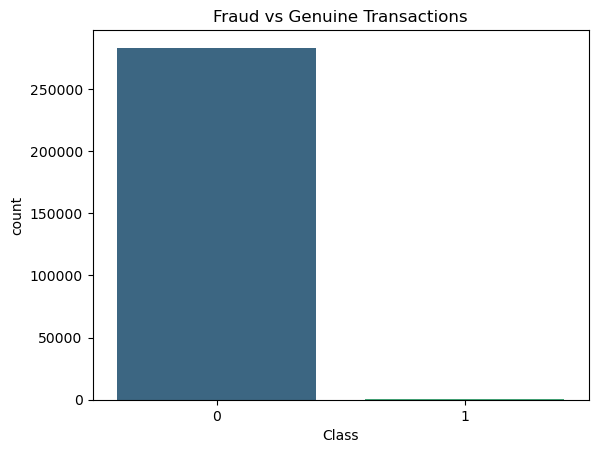

In [18]:
# Visualisation
sns.countplot(x='Class', data=df, palette='viridis', hue='Class', legend=False)
plt.title("Fraud vs Genuine Transactions")
plt.show()

# Exploratory Data Analysis

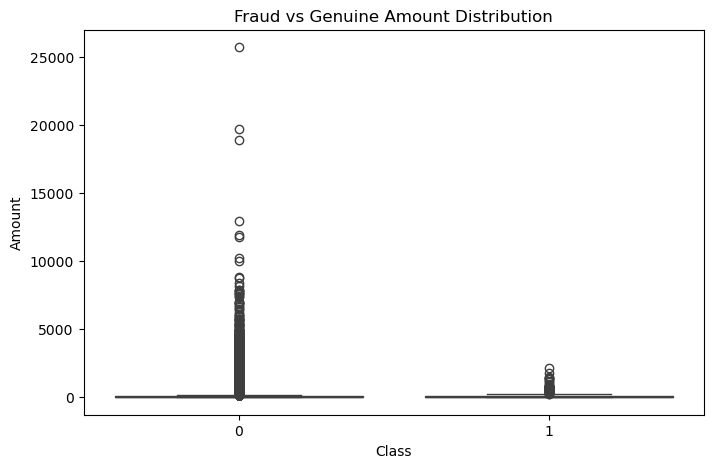

In [19]:
# Fraud vs Genuine Amount
plt.figure(figsize=(8,5))

sns.boxplot(x='Class',
            y='Amount',
            data=df)
plt.title('Fraud vs Genuine Amount Distribution')
plt.show()

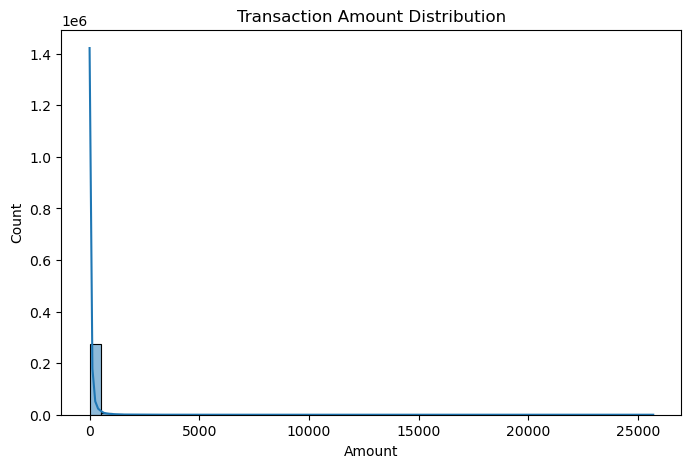

In [20]:
# Transaction Amount Distribution
plt.figure(figsize=(8,5))

sns.histplot(df['Amount'],
             bins=50,
             kde=True)
plt.title('Transaction Amount Distribution')
plt.show()

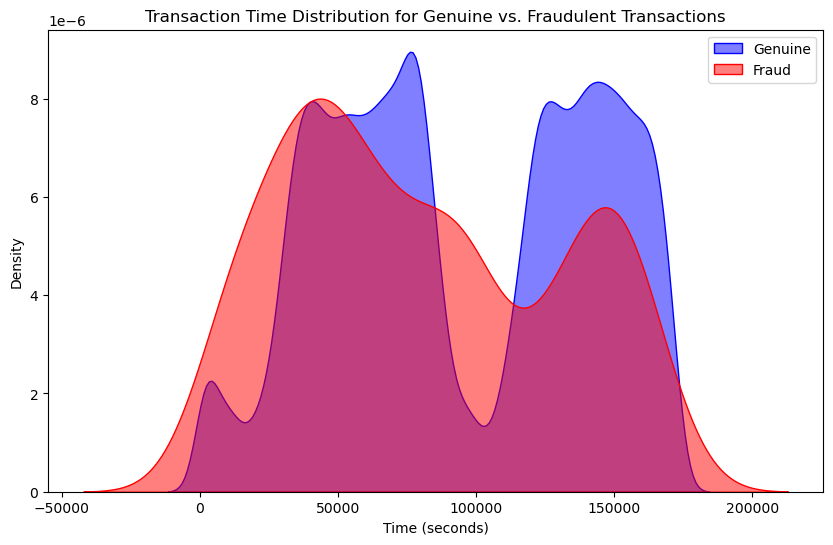

In [21]:
# Time Distribution for Fraud vs. Genuine Transactions
plt.figure(figsize=(10, 6))
sns.kdeplot(df[df['Class'] == 0]['Time'], label='Genuine', fill=True, color='blue', alpha=0.5)
sns.kdeplot(df[df['Class'] == 1]['Time'], label='Fraud', fill=True, color='red', alpha=0.5)
plt.title('Transaction Time Distribution for Genuine vs. Fraudulent Transactions')
plt.xlabel('Time (seconds)')
plt.ylabel('Density')
plt.legend()
plt.show()

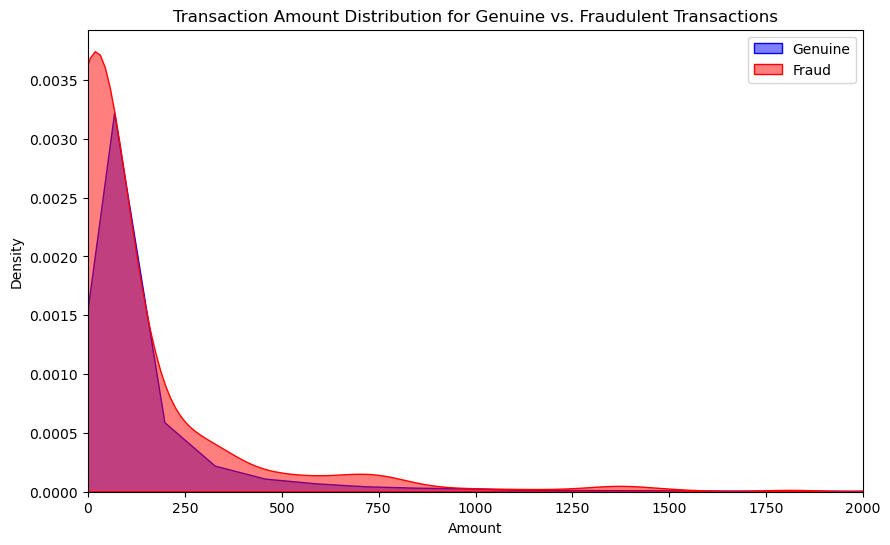

In [22]:
# Amount Distribution for Fraud vs. Genuine Transactions (KDE Plot)
plt.figure(figsize=(10, 6))
sns.kdeplot(df[df['Class'] == 0]['Amount'], label='Genuine', fill=True, color='blue', alpha=0.5)
sns.kdeplot(df[df['Class'] == 1]['Amount'], label='Fraud', fill=True, color='red', alpha=0.5)
plt.title('Transaction Amount Distribution for Genuine vs. Fraudulent Transactions')
plt.xlabel('Amount')
plt.ylabel('Density')
plt.legend()
plt.xlim(0, 2000)
plt.show()

In [23]:
# Finding features having the highest correlation with the target variable (Class)
corr_with_class = df.corr()['Class'].drop('Class').sort_values(key=abs, ascending=False)
print(corr_with_class.head(10))

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: Class, dtype: float64


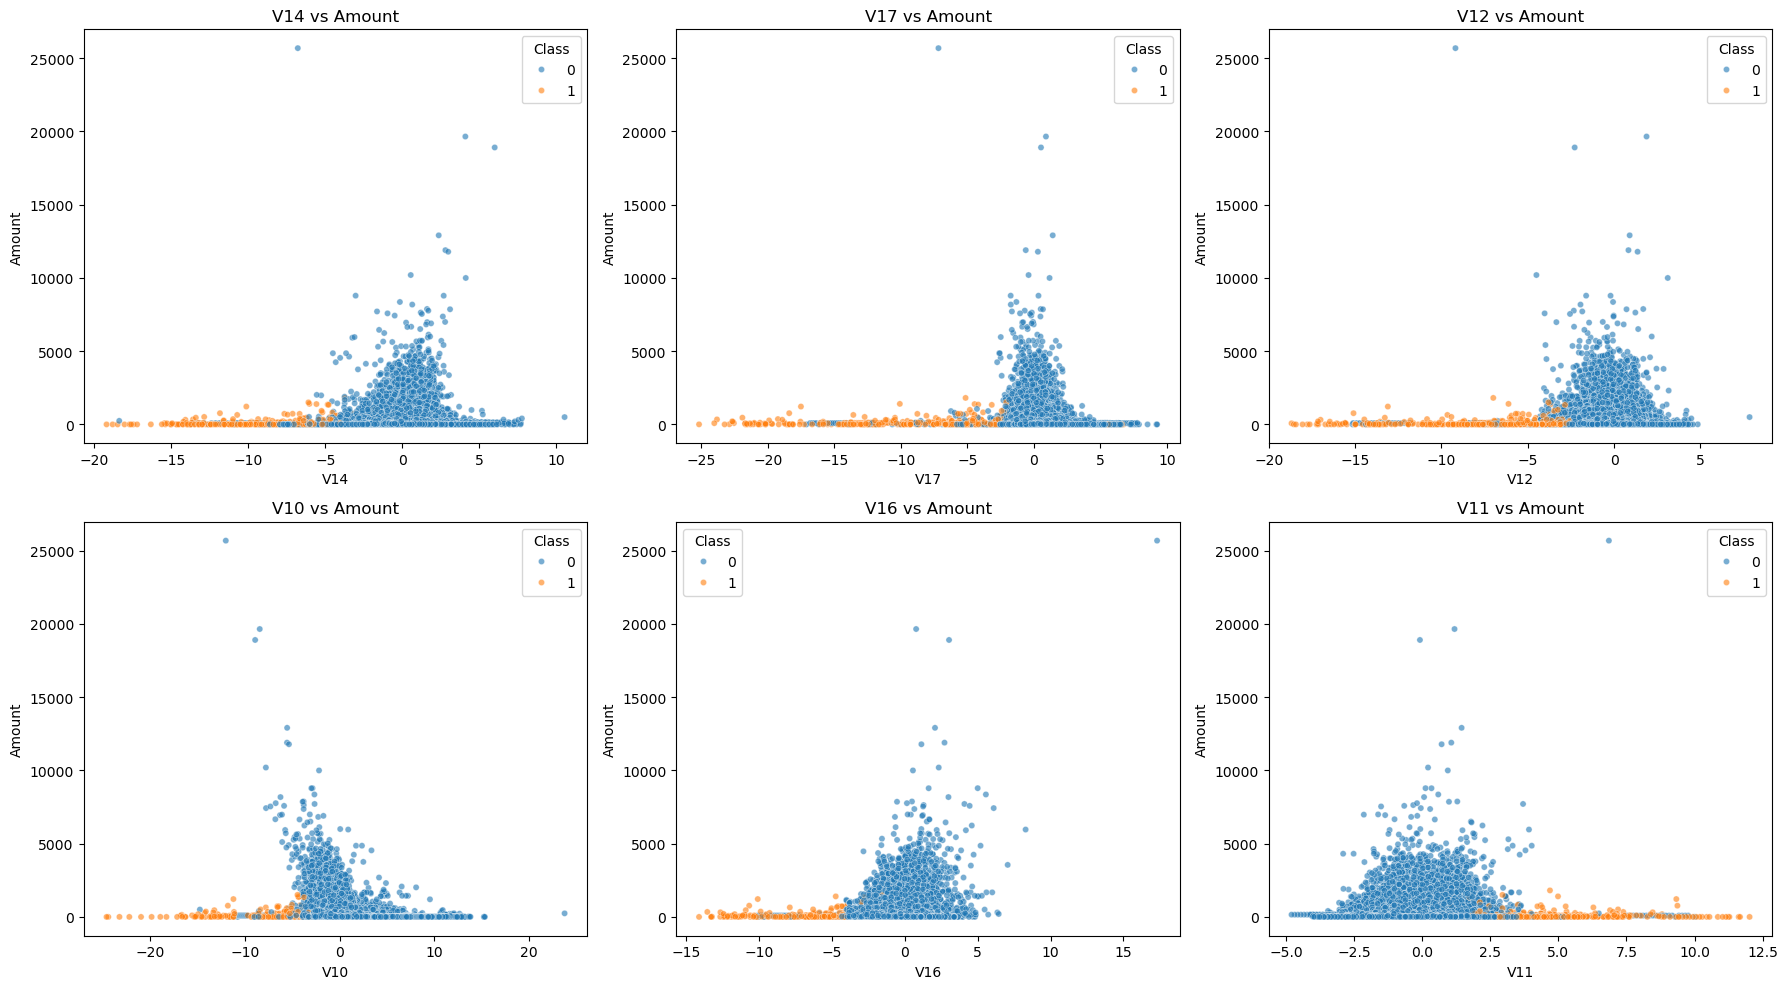

In [24]:
# Scatter plots of the top correlated features with the target variable

top_features = ['V14', 'V17', 'V12', 'V10', 'V16', 'V11']
plt.figure(figsize=(18, 10))
for i, feature in enumerate(top_features):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(
        data=df,
        x=feature,
        y='Amount',
        hue='Class',
        alpha=0.6,
        s=20
    )
    plt.title(f'{feature} vs Amount')
    plt.legend(title='Class', loc='best')
plt.tight_layout()
plt.show()

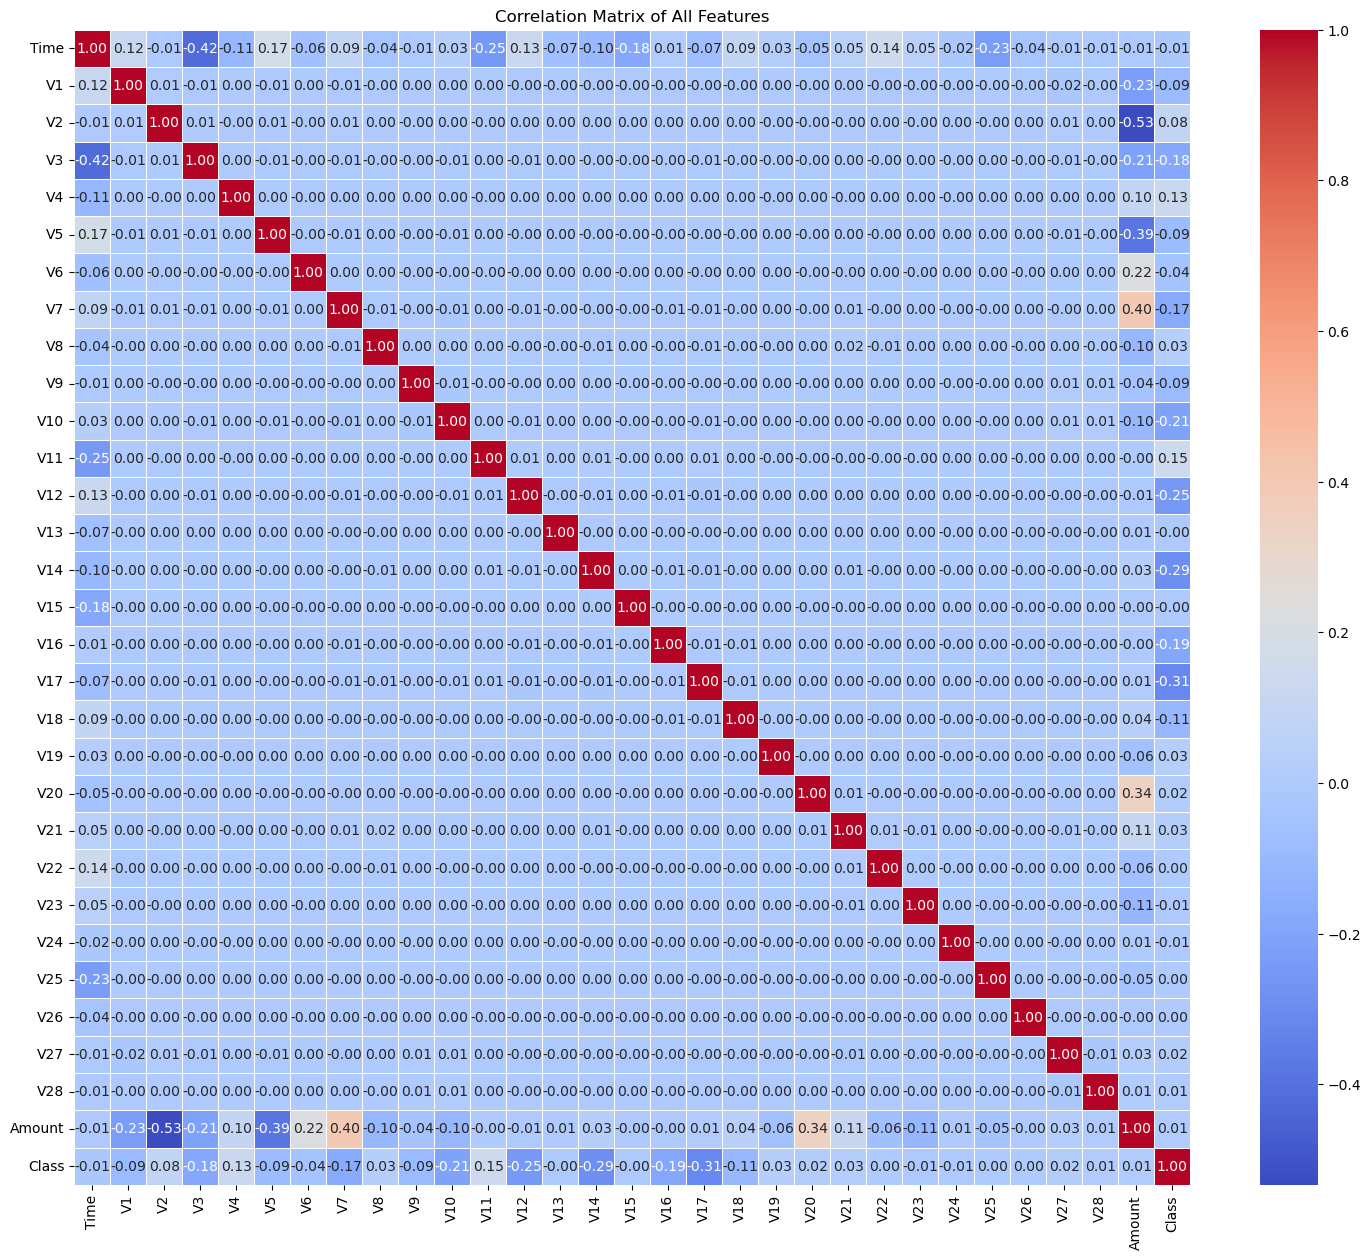

In [25]:
# Correlation Heatmap

plt.figure(figsize=(18, 15))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Matrix of All Features")
plt.show()

In [26]:
# Feature Scaling
scaler_time_amount = StandardScaler()
df[['Time', 'Amount']] = scaler_time_amount.fit_transform(df[['Time', 'Amount']])

In [27]:
# Feature Selection
X = df[['Time', 'Amount', 'V14', 'V17', 'V12', 'V10', 'V16', 'V11']]
y = df['Class']

In [28]:
# Train-Test Split
# Remove rows with NaN values in y (Class) and align X accordingly
valid_indices = y.dropna().index

X_filtered = X.loc[valid_indices]
y_filtered = y.loc[valid_indices]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_filtered,
    test_size=0.20,
    random_state=112,
    stratify=y_filtered
)

In [29]:
# Handling Imbalanced Dataset
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, class_weights))

print(f"Calculated Class Weights: {class_weights_dict}")

Calculated Class Weights: {np.int64(0): np.float64(0.5008340614822464), np.int64(1): np.float64(300.23809523809524)}


In [30]:
# Checking
y_train.value_counts()

Class
0    226602
1       378
Name: count, dtype: int64

# Model 1 Logistic Regression

In [31]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000, class_weight=class_weights_dict)
lr.fit(X_train, y_train)
prediction_lr = lr.predict(X_test)

In [32]:
# Evaluation Metrics
def evaluate_model(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_pred)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    print("\nConfusion Matrix (Normalized by True Labels):")
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens', cbar=False,
                xticklabels=['Genuine', 'Fraud'], yticklabels=['Genuine', 'Fraud'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Normalized Confusion Matrix')
    plt.show()

 Logistic Regression Evaluation (with Normalized Confusion Matrix) -
Accuracy: 0.9798
Precision: 0.0647
Recall: 0.8211
F1 Score: 0.1199
ROC AUC Score: 0.9006

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.82      0.12        95

    accuracy                           0.98     56746
   macro avg       0.53      0.90      0.55     56746
weighted avg       1.00      0.98      0.99     56746


Confusion Matrix (Normalized by True Labels):


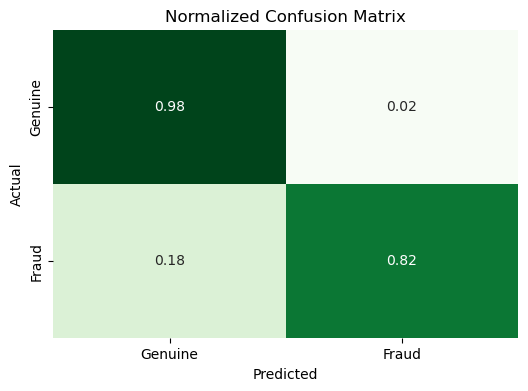

In [33]:
# Evaluation
print(' Logistic Regression Evaluation (with Normalized Confusion Matrix) -')
evaluate_model(y_test, prediction_lr)

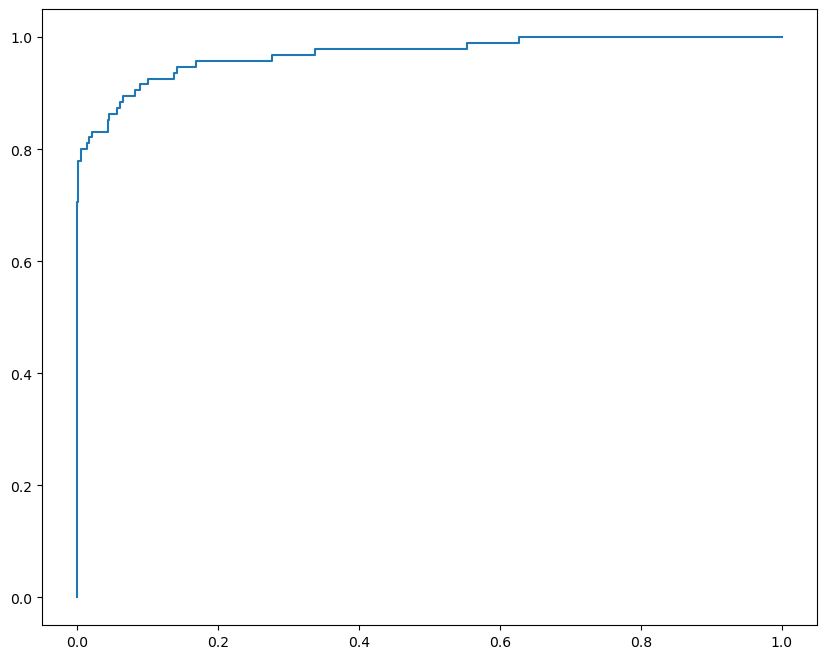

In [34]:
# Plotting ROC Curves
from sklearn.metrics import roc_curve
plt.figure(figsize=(10, 8))

# Logistic Regression
y_pred_proba_lr = lr.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_lr):.2f})')


# Model 2 Decision Tree

In [35]:
# Decision Tree
dt = DecisionTreeClassifier(random_state=112, class_weight=class_weights_dict)
dt.fit(X_train, y_train)
prediction_dt = dt.predict(X_test)

Accuracy: 0.9991
Precision: 0.7674
Recall: 0.6947
F1 Score: 0.7293
ROC AUC Score: 0.8472

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.77      0.69      0.73        95

    accuracy                           1.00     56746
   macro avg       0.88      0.85      0.86     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix (Normalized by True Labels):


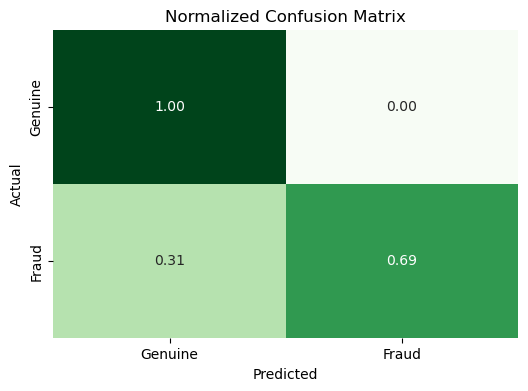

In [36]:
# Evaluation
evaluate_model(y_test, prediction_dt)

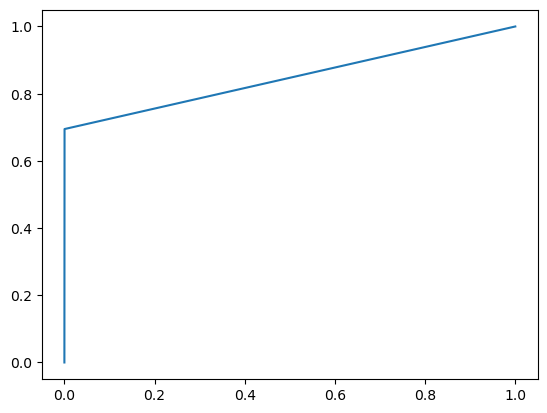

In [37]:
# ROC AUC Curve
y_pred_proba_dt = dt.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_proba_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_pred_proba_dt):.2f})')

# Model 3 Random Forest

In [38]:
# Random Forest
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=112,
    n_jobs=-1
)
rf.fit(X_train, y_train)
prediction_rf = rf.predict(X_test)

Accuracy: 0.9994
Precision: 0.8642
Recall: 0.7368
F1 Score: 0.7955
ROC AUC Score: 0.8683

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.86      0.74      0.80        95

    accuracy                           1.00     56746
   macro avg       0.93      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix (Normalized by True Labels):


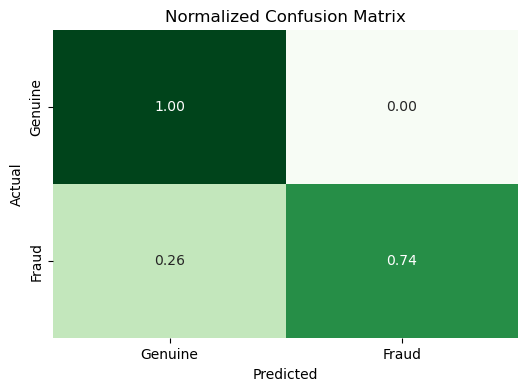

In [39]:
# Evaluation
evaluate_model(y_test, prediction_rf)

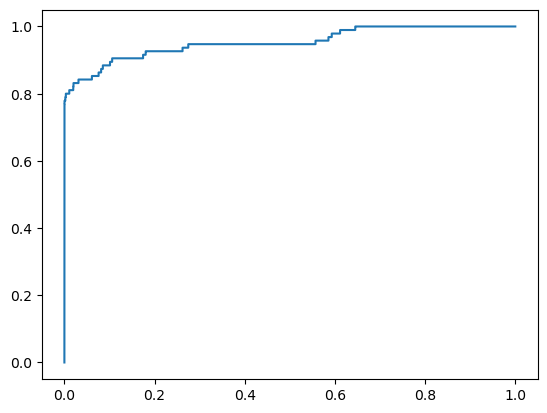

In [40]:
# ROC AUC Curve
y_pred_proba_rf = rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_pred_proba_rf):.2f})')

# Model 4 XGBoost

In [ ]:
# Improved XGBoost
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from xgboost import XGBClassifier

# Calculate scale_pos_weight based on class imbalance in y_train
neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
scale_pos_weight_value = neg_count / pos_count

params = {
    'max_depth': [3,4,5,6],
    'learning_rate': [0.01,0.05,0.1],
    'n_estimators': [200,400,600],
    'subsample': [0.8,1],
    'colsample_bytree': [0.8,1],
    'gamma': [0,1,3]
}

xgb = XGBClassifier(
    random_state=112,
    scale_pos_weight=scale_pos_weight_value,
    eval_metric='logloss'
)

search = RandomizedSearchCV(
    xgb,
    params,
    scoring='f1',
    cv=5,
    n_iter=20,
    n_jobs=-1,
    random_state=112
)

search.fit(X_train, y_train)
xgb = search.best_estimator_
prediction_xgb = xgb.predict(X_test)

In [ ]:
# Evaluation
prob = xgb.predict_proba(X_test)[:,1]

prediction_xgb = (prob >= 0.30).astype(int)

evaluate_model(y_test, prediction_xgb)

In [ ]:
# ROC AUC Curve
y_pred_proba_xgb = xgb.predict_proba(X_test)[:,1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_pred_proba_xgb):.2f})')

# Model 5 LightGBM

In [ ]:
# LightGBM
lgbm = LGBMClassifier(random_state=112, class_weight=class_weights_dict)
lgbm.fit(X_train, y_train)
prediction_lgbm = lgbm.predict(X_test)

In [ ]:
# Evaluation
evaluate_model(y_test, prediction_lgbm)

In [ ]:
# ROC AUC Curve
y_pred_proba_lgbm = lgbm.predict_proba(X_test)[:, 1]
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_pred_proba_lgbm)
plt.plot(fpr_lgbm, tpr_lgbm, label=f'LightGBM (AUC = {roc_auc_score(y_test, y_pred_proba_lgbm):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
# Model Comparison
model_names = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']
predictions = {
    'Logistic Regression': prediction_lr,
    'Decision Tree': prediction_dt,
    'Random Forest': prediction_rf,
    'XGBoost': prediction_xgb,
    'LightGBM': prediction_lgbm
}
metrics = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'ROC AUC Score': []
}
for model_name, prediction in predictions.items():
    metrics['Model'].append(model_name)
    metrics['Accuracy'].append(accuracy_score(y_test, prediction))
    metrics['Precision'].append(precision_score(y_test, prediction))
    metrics['Recall'].append(recall_score(y_test, prediction))
    metrics['F1 Score'].append(f1_score(y_test, prediction))
    metrics['ROC AUC Score'].append(roc_auc_score(y_test, prediction))
metrics_df = pd.DataFrame(metrics)
print("Model Comparison")
print(metrics_df)

In [ ]:
# Visualization of metrics
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20, 12))
axes = axes.flatten()
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC Score']
for i, metric in enumerate(metric_cols):
    sns.barplot(x='Model', y=metric, data=metrics_df, ax=axes[i], palette='viridis', hue='Model', legend=False)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis='x', rotation=45)
if len(metric_cols) < len(axes):
    fig.delaxes(axes[len(metric_cols)])
plt.tight_layout()
plt.suptitle('Comparison of Model Performance Metrics', y=1.02, fontsize=16)
plt.show()

# ROC Curve Comparison

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
plt.figure(figsize=(12, 8))

# Logistic Regression
y_pred_proba_lr = lr.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_lr):.4f})', color='purple')

# Decision Tree
y_pred_proba_dt = dt.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_proba_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_pred_proba_dt):.4f})', color='green')

# Random Forest
y_pred_proba_rf = rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_pred_proba_rf):.4f})', color='red')

# XGBoost
y_pred_proba_xgb = xgb.predict_proba(X_test)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_pred_proba_xgb):.4f})', color='blue')

# LightGBM
y_pred_proba_lgbm = lgbm.predict_proba(X_test)[:, 1]
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_pred_proba_lgbm)
plt.plot(fpr_lgbm, tpr_lgbm, label=f'LightGBM (AUC = {roc_auc_score(y_test, y_pred_proba_lgbm):.4f})', color='orange')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)') # Random classifier baseline
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison for All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
# Identify the Best Model based on F1 Score
best_model_row = metrics_df.loc[metrics_df['F1 Score'].idxmax()]
best_model_name = best_model_row['Model']
print(f"The best model based on F1 Score is: {best_model_name}")
print("Best Model Metrics:")
print(best_model_row)
if best_model_name == 'Random Forest':
    feature_importances = pd.Series(rf.feature_importances_, index=X.columns)
    plt.figure(figsize=(10, 6))
    feature_importances.nlargest(10).plot(kind='barh')
    plt.title('Random Forest Feature Importances (Best Model)')
    plt.xlabel('Feature Importance Score')
    plt.ylabel('Features')
    plt.show()
else:
    print(f"Feature importance visualization not implemented for {best_model_name} yet.")

In [ ]:
# Function for user input prediction
def predict_new_transaction(time, amount, v14, v17, v12, v10, v16, v11):
    input_data = pd.DataFrame([[time, amount, v14, v17, v12, v10, v16, v11]],
                                columns=X.columns)
    input_data[['Time', 'Amount']] = scaler_time_amount.transform(input_data[['Time', 'Amount']])
    prediction = rf.predict(input_data)
    prediction_proba = rf.predict_proba(input_data)[:, 1]

    result = "Fraudulent" if prediction[0] == 1 else "Genuine"
    print(f"Prediction: {result}")
    print(f"Probability of Fraud: {prediction_proba[0]:.4f}")
print("\n--- Test Prediction with Sample User Input ---")
print("Enter values for Time, Amount, V14, V17, V12, V10, V16, V11:")
sample_input_fraud = [406, 0, -2.609459, -3.136004, -0.626601, -0.933391, -0.228786, 0.449141]
print("\nPredicting for a sample potentially fraudulent transaction:")
predict_new_transaction(*sample_input_fraud)
sample_input_genuine = [0, 100, -0.311169, 0.207971, -0.617801, 0.090794, -0.470401, 0.449141]
print("\nPredicting for a sample genuine transaction:")
predict_new_transaction(*sample_input_genuine)
print("\nTo test with your own values, modify the `sample_input_fraud` or `sample_input_genuine` lists in the code above and run the cell.")